# 05. Аналіз і графіки
**Мета:** відповісти на питання 1–5 кейсу.

**Вхід:** `data/processed/final.parquet`, `candidates.parquet`, `precision_sample.xlsx`.

**Що робимо:** виключаємо 7 рядків з від'ємним інтервалом (n = 9 298); вибірка 60 тендерів для ручної перевірки точності фільтра; медіана, P80, P90 за категорією і процедурою; динаміка по кварталах; частка закупівель без конкуренції; графіки 1–3; експорт для дашборду.

**Результат:** БпЛА через каталог 9 / 13 днів (медіана / P80), відкриті торги 20 / 25, РЕБ 21 / 27; з 2023 року цикл стабільний.

**Вихід:** `screenshots/chart1_main.png`, `chart2_trend.png`, `chart3_procedures.png`, `data/processed/dashboard.csv`.

In [1]:
import duckdb
con = duckdb.connect()

In [2]:
con.sql("""
    CREATE OR REPLACE TABLE f AS
    SELECT * FROM '../data/processed/final.parquet'
    WHERE d_award_to_contract >= 0          -- правило 3: 7 рядків виключено
""")

con.sql("""
    SELECT category, procurement_method, COUNT(*) AS n,
           quantile_cont(days_total, 0.5) AS old_p50,
           quantile_cont(d_total, 0.5)    AS new_p50,
           quantile_cont(days_total, 0.9) AS old_p90,
           quantile_cont(d_total, 0.9)    AS new_p90,
           quantile_cont(d_to_award, 0.5)          AS award_p50,
           quantile_cont(d_award_to_contract, 0.5) AS contract_p50,
           quantile_cont(d_total, 0.8)             AS new_p80
    FROM f
    GROUP BY ALL
    ORDER BY category, procurement_method
""").df()

,category,procurement_method,n,old_p50,new_p50,old_p90,new_p90,award_p50,contract_p50,new_p80
0,БпЛА,open,2920,20.0,20.0,28.0,28.0,11.0,8.0,25.0
1,БпЛА,selective,5194,9.0,9.0,16.0,16.0,5.0,4.0,13.0
2,Керування і зв'язок,open,49,19.0,19.0,26.0,26.0,9.0,7.0,24.0
3,РЕБ,open,1053,21.0,21.0,29.0,29.0,12.0,8.0,27.0
4,Розвідка і виявлення,open,82,18.0,18.0,23.9,23.9,9.5,7.0,21.8


In [3]:
sample = con.sql("""
    SELECT category, tender_id, title, item_desc, award_value
    FROM f
    WHERE category IN ('БпЛА', 'РЕБ')
    QUALIFY ROW_NUMBER() OVER (PARTITION BY category ORDER BY hash(tender_id)) <= 30
""").df()

sample['is_target'] = ''      # сюди ти вручну ставиш 1 (дрон/РЕБ) або 0 (ні)
sample.to_excel('../data/processed/precision_sample.xlsx', index=False)
len(sample)

60

In [4]:
import pandas as pd
chk = pd.read_excel('../data/processed/precision_sample.xlsx')
chk.groupby('category')['is_target'].agg(['count', 'sum', 'mean'])

,count,sum,mean
category,,,
БпЛА,0,0.0,NaN
РЕБ,0,0.0,NaN


In [5]:
# Динаміка по кварталах (за датою оголошення)
q3 = con.sql("""
    SELECT category, procurement_method,
           date_trunc('quarter', tender_start_date) AS quarter,
           COUNT(*) AS n,
           quantile_cont(d_total, 0.5) AS p50,
           quantile_cont(d_total, 0.8) AS p80
    FROM f
    WHERE category IN ('БпЛА', 'РЕБ')
    GROUP BY ALL
    ORDER BY category, procurement_method, quarter
""").df()
q3

,category,procurement_method,quarter,n,p50,p80
0,БпЛА,open,2022-07-01 00:00:00+03:00,18,11.0,13.8
1,БпЛА,open,2022-10-01 00:00:00+03:00,19,20.0,24.0
2,БпЛА,open,2023-01-01 00:00:00+02:00,42,21.0,26.8
3,БпЛА,open,2023-04-01 00:00:00+03:00,76,21.0,25.0
4,БпЛА,open,2023-07-01 00:00:00+03:00,194,21.0,26.0
5,БпЛА,open,2023-10-01 00:00:00+03:00,320,21.0,26.0
6,БпЛА,open,2024-01-01 00:00:00+02:00,384,21.0,26.0
7,БпЛА,open,2024-04-01 00:00:00+03:00,377,21.0,26.0
8,БпЛА,open,2024-07-01 00:00:00+03:00,295,20.0,26.0
9,БпЛА,open,2024-10-01 00:00:00+03:00,255,19.0,24.0


In [6]:
# Частка закупівель без конкурентної процедури
q4 = con.sql("""
    SELECT category, year,
           COUNT(*) AS n_all,
           SUM(CASE WHEN procurement_method = 'limited' THEN 1 ELSE 0 END) AS n_limited,
           ROUND(100.0 * SUM(CASE WHEN procurement_method = 'limited' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_limited
    FROM '../data/processed/candidates.parquet'
    WHERE category IN ('БпЛА', 'РЕБ')
    GROUP BY ALL
    ORDER BY category, year
""").df()
q4

,category,year,n_all,n_limited,pct_limited
0,БпЛА,2022,160,120.0,75.0
1,БпЛА,2023,1964,1101.0,56.1
2,БпЛА,2024,4926,1508.0,30.6
3,БпЛА,2025,5559,1760.0,31.7
4,РЕБ,2022,11,8.0,72.7
5,РЕБ,2023,130,72.0,55.4
6,РЕБ,2024,1124,567.0,50.4
7,РЕБ,2025,1096,660.0,60.2


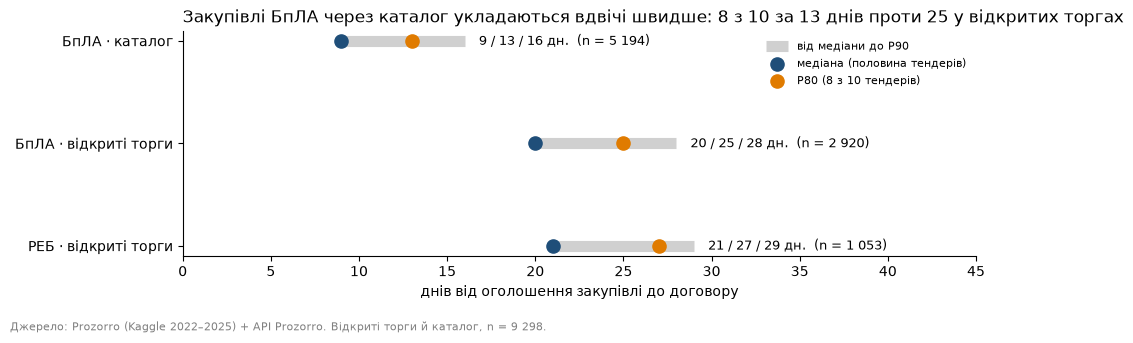

In [28]:
import matplotlib.pyplot as plt

m = con.sql("""
    SELECT category || ' · ' ||
           CASE procurement_method WHEN 'selective' THEN 'каталог' ELSE 'відкриті торги' END AS grp,
           COUNT(*) AS n,
           quantile_cont(d_total, 0.5) AS p50,
           quantile_cont(d_total, 0.8) AS p80,
           quantile_cont(d_total, 0.9) AS p90
    FROM f
    WHERE category IN ('БпЛА', 'РЕБ')
    GROUP BY 1
    ORDER BY p50 DESC
""").df()

fig, ax = plt.subplots(figsize=(10, 3.2))
y = range(len(m))
ax.hlines(y, m.p50, m.p90, color='#d0d0d0', lw=8, label='від медіани до P90')
ax.scatter(m.p50, y, color='#1f4e79', s=90, zorder=3, label='медіана (половина тендерів)')
ax.scatter(m.p80, y, color='#e07b00', s=90, zorder=3, label='P80 (8 з 10 тендерів)')
for i, r in m.iterrows():
    ax.text(r.p90 + 0.8, i, f'{r.p50:.0f} / {r.p80:.0f} / {r.p90:.0f} дн.  (n = {r.n:,})'.replace(',', ' '),
            va='center', fontsize=9)

ax.set_yticks(list(y)); ax.set_yticklabels(m.grp)
ax.set_xlim(0, 45)
ax.set_xlabel('днів від оголошення закупівлі до договору')
ax.set_title('Закупівлі БпЛА через каталог укладаються вдвічі швидше: 8 з 10 за 13 днів проти 25 у відкритих торгах', loc='left', fontsize=12)
ax.legend(frameon=False, fontsize=8, loc='upper right')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
fig.text(0.01, -0.05, 'Джерело: Prozorro (Kaggle 2022–2025) + API Prozorro. Відкриті торги й каталог, n = 9 298.',
         fontsize=8, color='gray')
plt.tight_layout()
plt.savefig('../screenshots/chart1_main.png', dpi=200, bbox_inches='tight')
plt.show()

In [8]:
import pandas as pd
chk = pd.read_excel('../data/processed/precision_sample.xlsx')
chk.groupby('category')['is_target'].agg(['count', 'sum', 'mean'])

,count,sum,mean
category,,,
БпЛА,30,30,1.000000
РЕБ,30,29,0.966667


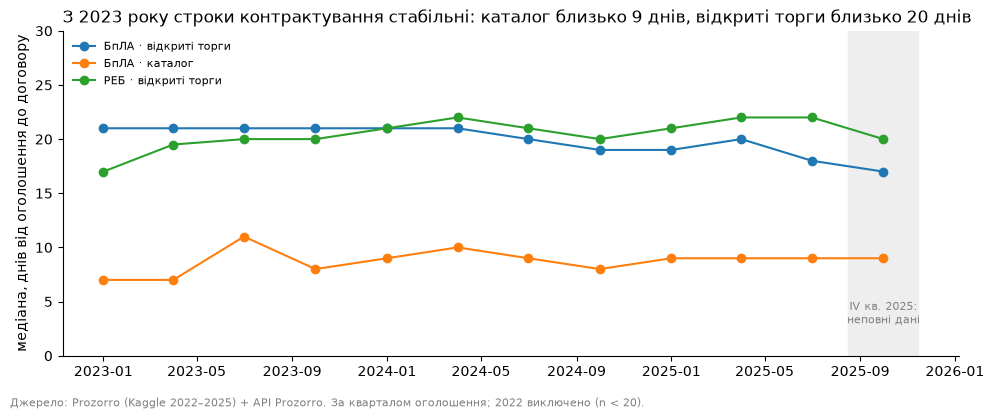

In [27]:
q = q3.copy()
q['q'] = q['quarter'].dt.tz_localize(None)                 # прибираємо часовий пояс
q = q[q['q'] >= '2023-01-01']                              # 2022 рік: замало тендерів
q['grp'] = q['category'] + ' · ' + q['procurement_method'].map({'selective': 'каталог', 'open': 'відкриті торги'})

fig, ax = plt.subplots(figsize=(10, 4))
for g, d in q.groupby('grp'):
    d = d.sort_values('q')
    ax.plot(d['q'], d['p50'], marker='o', label=g)

last = q['q'].max()
ax.axvspan(last - pd.Timedelta(days=45), last + pd.Timedelta(days=45), color='#eeeeee', zorder=0)
ax.text(last, 3, 'IV кв. 2025:\nнеповні дані', ha='center', fontsize=8, color='gray')

ax.set_ylim(0, 30)
ax.set_ylabel('медіана, днів від оголошення до договору')
ax.set_title('З 2023 року строки контрактування стабільні: каталог близько 9 днів, відкриті торги близько 20 днів', loc='left', fontsize=12)
ax.legend(frameon=False, fontsize=8, loc='upper left')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
fig.text(0.01, -0.03, 'Джерело: Prozorro (Kaggle 2022–2025) + API Prozorro. За кварталом оголошення; 2022 виключено (n < 20).',
         fontsize=8, color='gray')
plt.tight_layout()
plt.savefig('../screenshots/chart2_trend.png', dpi=200, bbox_inches='tight')
plt.show()

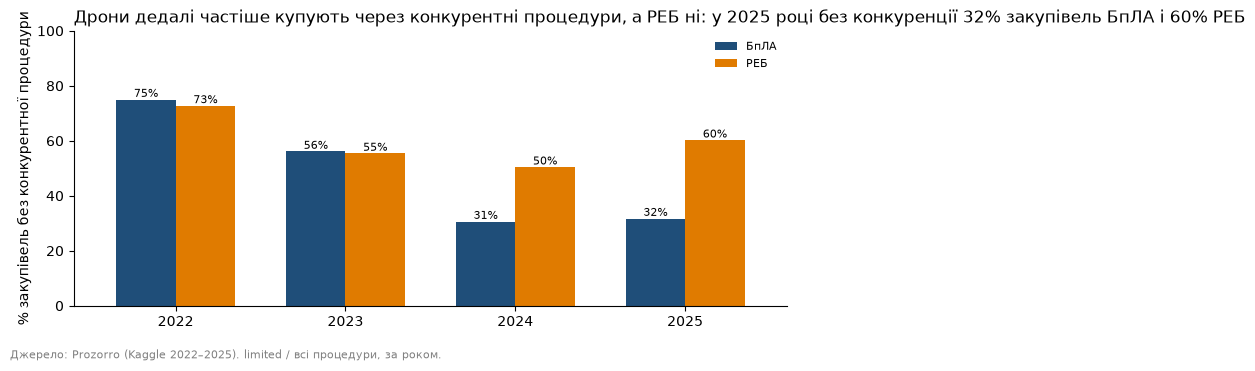

In [18]:
p = q4.pivot(index='year', columns='category', values='pct_limited')

fig, ax = plt.subplots(figsize=(8, 3.5))
p.plot(kind='bar', ax=ax, color=['#1f4e79', '#e07b00'], rot=0, width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f%%', fontsize=8)
ax.set_ylim(0, 100)
ax.set_xlabel('')
ax.set_ylabel('% закупівель без конкурентної процедури')
ax.set_title('Закупівлі без конкурентної процедури зменшуються', loc='left', fontsize=12)
ax.legend(frameon=False, fontsize=8)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
fig.text(0.01, -0.04, 'Джерело: Prozorro (Kaggle 2022–2025). limited / всі процедури, за роком.', fontsize=8, color='gray')
plt.tight_layout()
plt.savefig('../screenshots/chart3_limited.png', dpi=200, bbox_inches='tight')
plt.show()

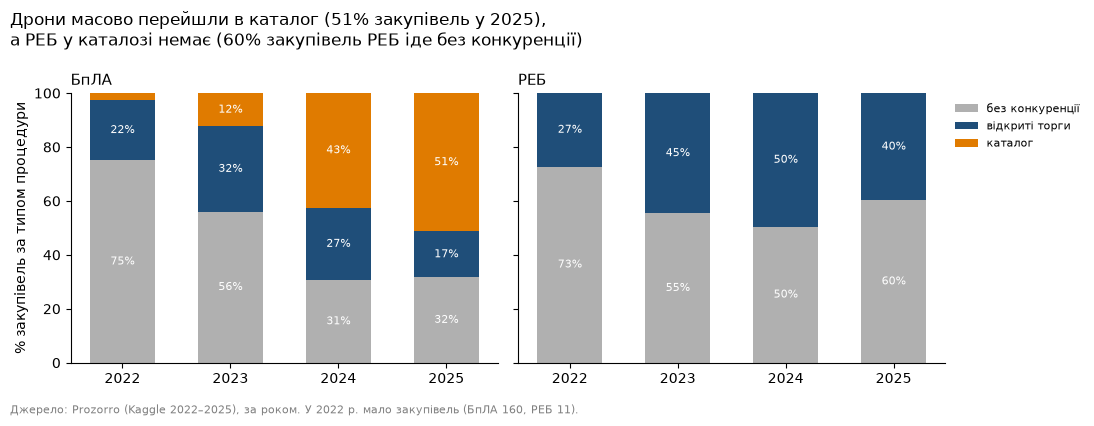

In [24]:
mix = con.sql("""
    SELECT category, year, procurement_method, COUNT(*) AS n
    FROM '../data/processed/candidates.parquet'
    WHERE category IN ('БпЛА', 'РЕБ')
    GROUP BY ALL
""").df()

mix['pct'] = 100 * mix['n'] / mix.groupby(['category', 'year'])['n'].transform('sum')

order  = ['limited', 'open', 'selective']
labels = {'limited': 'без конкуренції', 'open': 'відкриті торги', 'selective': 'каталог'}
colors = {'limited': '#b0b0b0', 'open': '#1f4e79', 'selective': '#e07b00'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cat in zip(axes, ['БпЛА', 'РЕБ']):
    p = (mix[mix['category'] == cat]
         .pivot(index='year', columns='procurement_method', values='pct')
         .reindex(columns=order).fillna(0))
    bottom = 0
    for m in order:
        bars = ax.bar(p.index.astype(str), p[m], bottom=bottom,
                      color=colors[m], label=labels[m], width=0.6)
        ax.bar_label(bars, labels=[f'{v:.0f}%' if v >= 5 else '' for v in p[m]],
                     label_type='center', fontsize=8, color='white')
        bottom = bottom + p[m]
    ax.set_title(cat, loc='left', fontsize=11)
    ax.set_ylim(0, 100)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)

axes[0].set_ylabel('% закупівель за типом процедури')
axes[1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.suptitle('Дрони масово перейшли в каталог (51% закупівель у 2025),\nа РЕБ у каталозі немає (60% закупівель РЕБ іде без конкуренції)', x=0.01, ha='left', fontsize=12)
fig.text(0.01, -0.03, 'Джерело: Prozorro (Kaggle 2022–2025), за роком. У 2022 р. мало закупівель (БпЛА 160, РЕБ 11).',
         fontsize=8, color='gray')
plt.tight_layout()
plt.savefig('../screenshots/chart3_procedures.png', dpi=200, bbox_inches='tight')
plt.show()

In [25]:
con.sql("""
    COPY (
        SELECT tender_id, category,
               CASE procurement_method WHEN 'selective' THEN 'каталог' ELSE 'відкриті торги' END AS method,
               CAST(date_trunc('quarter', tender_start_date) AS DATE) AS quarter,
               year,
               d_to_award, d_award_to_contract, d_total
        FROM f
    ) TO '../data/processed/dashboard.csv' (HEADER, DELIMITER ',')
""")